<a href="https://colab.research.google.com/github/am6219344-creator/Analisis_Economia_Peru/blob/main/TA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

nombre_archivo = "Economia_Peru.csv"
ruta_drive = "/content/drive/MyDrive"

ruta_csv = None

for carpeta, subcarpetas, archivos in os.walk(ruta_drive):
    if nombre_archivo in archivos:
        ruta_csv = os.path.join(carpeta, nombre_archivo)
        break

if ruta_csv is not None:
    df = pd.read_csv(ruta_csv)
    print("Archivo cargado correctamente.")
    print("Ubicación:", ruta_csv)
    print("Cantidad de registros:", df.shape[0])
    print("Cantidad de columnas:", df.shape[1])
else:
    print("No se encontró Economia_Peru.csv en Mi unidad.")
    print("Verifica el nombre y la ubicación del archivo.")

Archivo cargado correctamente.
Ubicación: /content/drive/MyDrive/TA3/Economia_Peru.csv
Cantidad de registros: 8000
Cantidad de columnas: 12


In [4]:
print("Nombres de las columnas:")
print(df.columns.tolist())

print("\nPrimeras 10 filas:")
display(df.head(10))

print("\nInformación general:")
df.info()

print("\nValores faltantes por columna:")
print(df.isnull().sum())

Nombres de las columnas:
['ID_registro', 'Fecha', 'Año', 'Mes', 'Region', 'Indicador', 'Valor', 'Unidad', 'Descripcion', 'Indice_empleo_formal_simulado', 'Poblacion_referencia_millones_simulada', 'Es_dato_simulado']

Primeras 10 filas:


,ID_registro,Fecha,Año,Mes,Region,Indicador,Valor,Unidad,Descripcion,Indice_empleo_formal_simulado,Poblacion_referencia_millones_simulada,Es_dato_simulado
0,PER006929,2005-01-01,2005,1,Arequipa,Inflación,4.560,% anual (simulado),Variación anual simulada del índice de precios,114.79,1.568,True
1,PER005843,2005-01-01,2005,1,Arequipa,PBI,8.530,% variación anual (simulado),Crecimiento anual simulado del PBI real,86.81,1.536,True
2,PER000381,2005-01-01,2005,1,Arequipa,Tipo de cambio,3.213,S/ por US$ (simulado),Tipo de cambio nominal simulado,73.16,1.660,True
3,PER004005,2005-01-01,2005,1,Arequipa,Tipo de cambio,3.087,S/ por US$ (simulado),Tipo de cambio nominal simulado,103.00,1.543,True
4,PER004901,2005-01-01,2005,1,Cusco,Inflación,3.430,% anual (simulado),Variación anual simulada del índice de precios,107.06,1.298,True
5,PER001869,2005-01-01,2005,1,Cusco,PBI,10.160,% variación anual (simulado),Crecimiento anual simulado del PBI real,92.58,1.315,True
6,PER007073,2005-01-01,2005,1,Cusco,Tipo de cambio,3.121,S/ por US$ (simulado),Tipo de cambio nominal simulado,108.40,1.367,True
7,PER004532,2005-01-01,2005,1,Ica,Empleo,2.540,% desempleo (simulado),Tasa de desempleo simulada por región,98.94,0.970,True
8,PER002736,2005-01-01,2005,1,Ica,Tipo de cambio,3.226,S/ por US$ (simulado),Tipo de cambio nominal simulado,106.30,1.014,True
9,PER000780,2005-01-01,2005,1,Junín,Empleo,8.310,% desempleo (simulado),Tasa de desempleo simulada por región,95.98,1.068,True



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 12 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   ID_registro                             8000 non-null   object 
 1   Fecha                                   8000 non-null   object 
 2   Año                                     8000 non-null   int64  
 3   Mes                                     8000 non-null   int64  
 4   Region                                  8000 non-null   object 
 5   Indicador                               8000 non-null   object 
 6   Valor                                   8000 non-null   float64
 7   Unidad                                  8000 non-null   object 
 8   Descripcion                             8000 non-null   object 
 9   Indice_empleo_formal_simulado           8000 non-null   float64
 10  Poblacion_referencia_millones_simulada

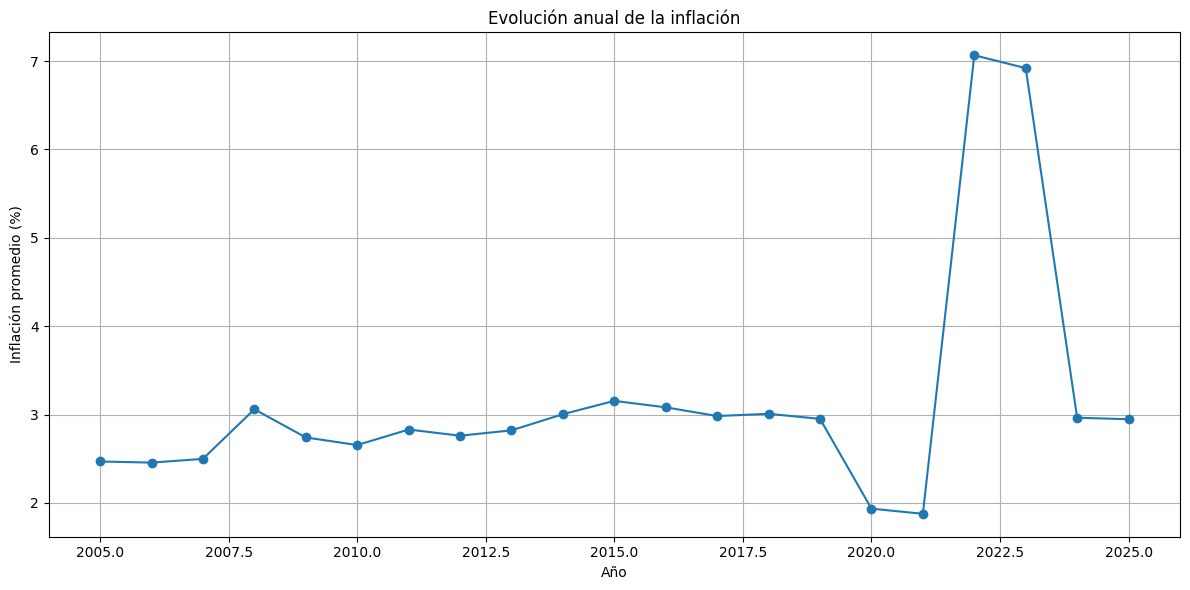

In [5]:
inflacion = df[df["Indicador"] == "Inflación"].copy()

inflacion_anual = (
    inflacion.groupby("Año")["Valor"]
    .mean()
    .reset_index()
    .sort_values("Año")
)

plt.figure(figsize=(12, 6))
plt.plot(
    inflacion_anual["Año"],
    inflacion_anual["Valor"],
    marker="o"
)

plt.title("Evolución anual de la inflación")
plt.xlabel("Año")
plt.ylabel("Inflación promedio (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig("grafico_inflacion.png", dpi=300)
plt.show()

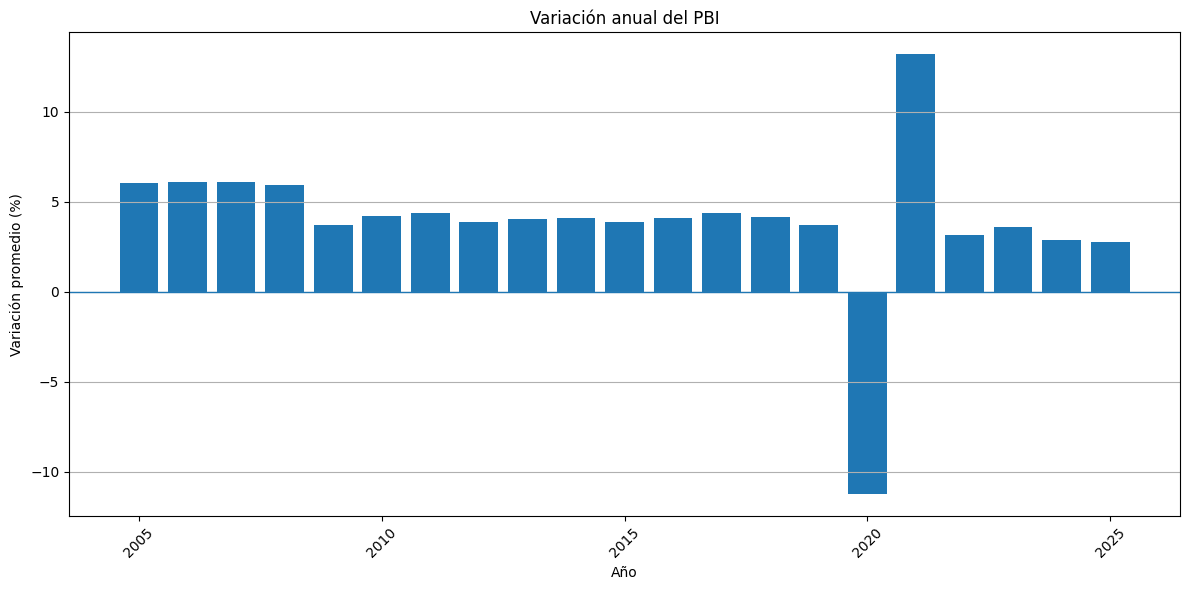

In [6]:
pbi = df[df["Indicador"] == "PBI"].copy()

pbi_anual = (
    pbi.groupby("Año")["Valor"]
    .mean()
    .reset_index()
    .sort_values("Año")
)

plt.figure(figsize=(12, 6))
plt.bar(pbi_anual["Año"], pbi_anual["Valor"])
plt.axhline(y=0, linewidth=1)

plt.title("Variación anual del PBI")
plt.xlabel("Año")
plt.ylabel("Variación promedio (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("grafico_pbi.png", dpi=300)
plt.show()

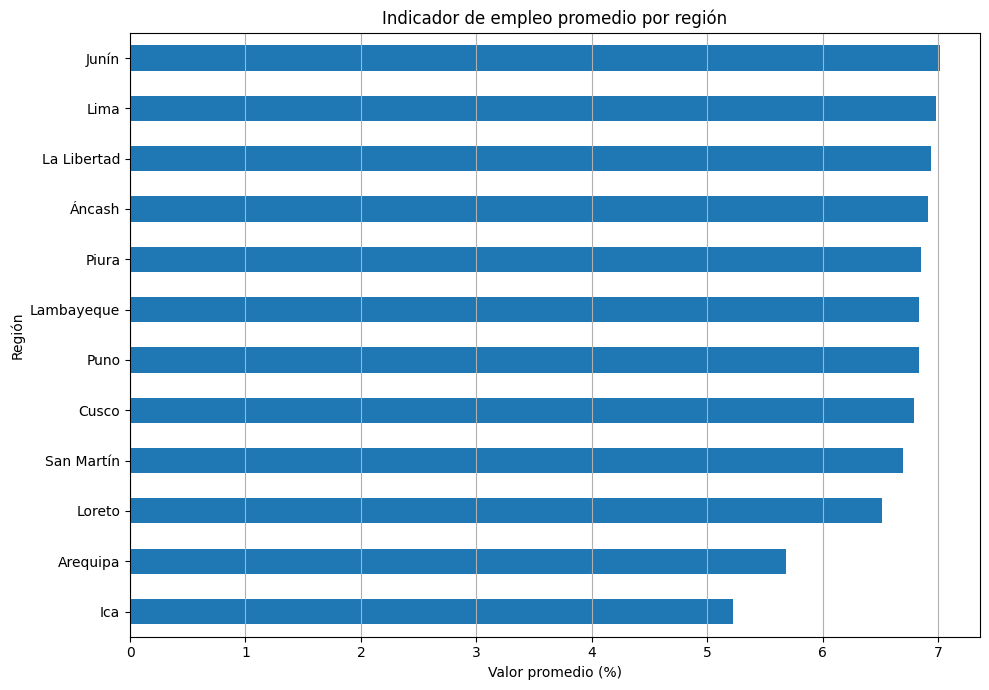

In [7]:
empleo = df[df["Indicador"] == "Empleo"].copy()

desempleo_region = (
    empleo.groupby("Region")["Valor"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 7))
desempleo_region.plot(kind="barh")

plt.title("Indicador de empleo promedio por región")
plt.xlabel("Valor promedio (%)")
plt.ylabel("Región")
plt.grid(axis="x")
plt.tight_layout()
plt.savefig("grafico_empleo_regiones.png", dpi=300)
plt.show()


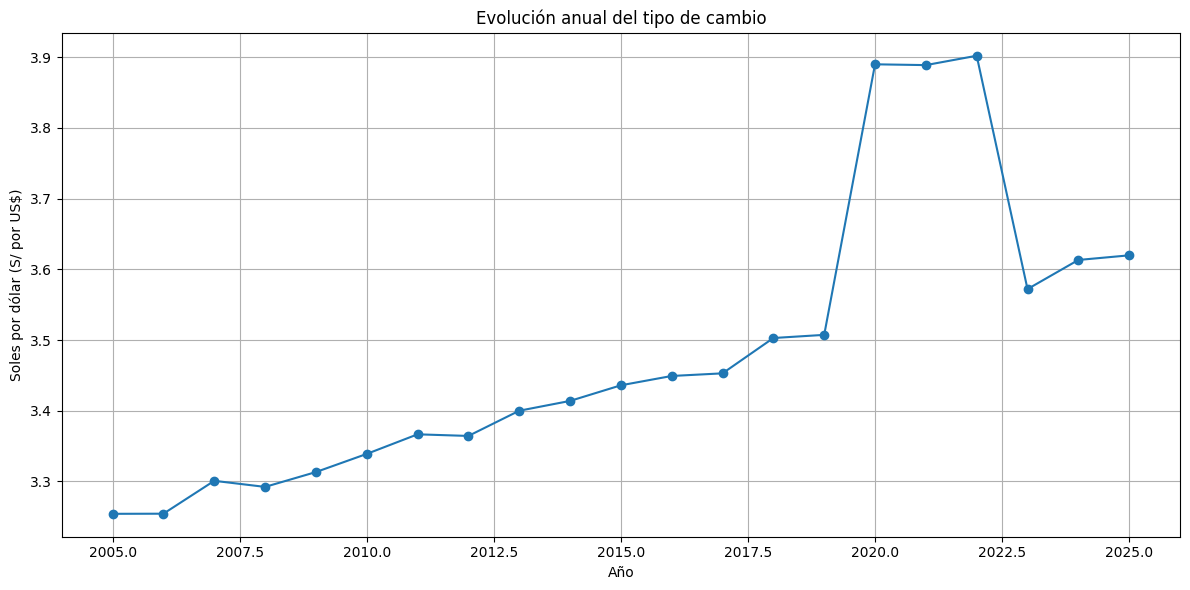

In [8]:
tipo_cambio = df[
    df["Indicador"] == "Tipo de cambio"
].copy()

cambio_anual = (
    tipo_cambio.groupby("Año")["Valor"]
    .mean()
    .reset_index()
    .sort_values("Año")
)

plt.figure(figsize=(12, 6))
plt.plot(
    cambio_anual["Año"],
    cambio_anual["Valor"],
    marker="o"
)

plt.title("Evolución anual del tipo de cambio")
plt.xlabel("Año")
plt.ylabel("Soles por dólar (S/ por US$)")
plt.grid(True)
plt.tight_layout()
plt.savefig("grafico_tipo_cambio.png", dpi=300)
plt.show()

In [9]:
resumen = (
    df.groupby(["Año", "Indicador"])["Valor"]
    .agg(["mean", "min", "max", "count"])
    .round(2)
    .reset_index()
)

resumen.columns = [
    "Año",
    "Indicador",
    "Promedio",
    "Mínimo",
    "Máximo",
    "Cantidad"
]

display(resumen)

resumen.to_csv(
    "resumen_economia_peru.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tabla resumen creada correctamente.")

,Año,Indicador,Promedio,Mínimo,Máximo,Cantidad
0,2005,Empleo,6.30,2.00,9.45,113
1,2005,Inflación,2.47,-0.73,5.14,98
2,2005,PBI,6.07,0.90,11.02,68
3,2005,Tipo de cambio,3.25,2.96,3.61,70
4,2006,Empleo,6.52,2.47,9.19,115
...,...,...,...,...,...,...
79,2024,Tipo de cambio,3.61,3.34,3.94,81
80,2025,Empleo,6.29,2.35,10.64,105
81,2025,Inflación,2.95,0.13,6.06,111
82,2025,PBI,2.79,-1.67,8.67,79


Tabla resumen creada correctamente.


In [10]:
from google.colab import files
import zipfile
import os

archivos = [
    "grafico_inflacion.png",
    "grafico_pbi.png",
    "grafico_empleo_regiones.png",
    "grafico_tipo_cambio.png",
    "resumen_economia_peru.csv"
]

with zipfile.ZipFile(
    "resultados_economia_peru.zip", "w"
) as archivo_zip:

    for archivo in archivos:
        if os.path.exists(archivo):
            archivo_zip.write(archivo)

files.download("resultados_economia_peru.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
contenido_readme = """
# Análisis exploratorio de la economía del Perú

## 1. Introducción
Este proyecto realiza un análisis exploratorio de indicadores
económicos mediante Python y Google Colab.

## 2. Objetivo
Analizar la evolución de los indicadores económicos disponibles
en la base de datos y representarlos mediante gráficos.

## 3. Herramientas utilizadas
- Python
- Google Colab
- Pandas
- Matplotlib
- GitHub

## 4. Metodología
Se cargó la base de datos en formato CSV, se revisaron sus
columnas y registros, se calcularon promedios por año y región,
y se elaboraron gráficos y tablas de resumen.

## 5. Resultados
El proyecto incluye gráficos de inflación, PBI, empleo y tipo
de cambio, además de una tabla resumen por año e indicador.

Las conclusiones específicas deben redactarse después de
observar los gráficos y verificar los resultados obtenidos.

## 6. Archivos del proyecto
- Analisis_Economia_Peru.ipynb: cuaderno de análisis.
- Economia_Peru.csv: base de datos original.
- grafico_inflacion.png: gráfico de inflación.
- grafico_pbi.png: gráfico del PBI.
- grafico_empleo_regiones.png: gráfico por región.
- grafico_tipo_cambio.png: gráfico del tipo de cambio.
- resumen_economia_peru.csv: tabla resumen.

## 7. Nota sobre los datos
Verificar la procedencia de la base de datos antes de publicar
conclusiones. Si contiene datos simulados, no deben presentarse
como estadísticas oficiales o reales del Perú.
"""

with open("README.md", "w", encoding="utf-8") as archivo:
    archivo.write(contenido_readme)

print("README.md creado correctamente.")

README.md creado correctamente.


In [14]:
import os
import shutil

carpeta_resultados = (
    "/content/drive/MyDrive/Resultados_Economia_Peru"
)

os.makedirs(carpeta_resultados, exist_ok=True)

archivos = [
    "grafico_inflacion.png",
    "grafico_pbi.png",
    "grafico_empleo_regiones.png",
    "grafico_tipo_cambio.png",
    "resumen_economia_peru.csv",
    "README.md"
]

for archivo in archivos:
    if os.path.exists(archivo):
        shutil.copy2(
            archivo,
            os.path.join(carpeta_resultados, archivo)
        )

print("Resultados guardados en:", carpeta_resultados)

Resultados guardados en: /content/drive/MyDrive/Resultados_Economia_Peru


In [15]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>